In [103]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math as mt

import warnings
warnings.filterwarnings('ignore')
pd.set_option("display.max_column",60)

In [107]:
df = pd.read_csv("data/Train.csv")
test = pd.read_csv("data/Test.csv")

In [3]:
columns = ["LandPreparationMethod", "FirstTopDressFert", "CropbasalFerts", "TransDetFactor", "NursDetFactor"]

for column in columns:
    n_column = df[column].map(str).apply(lambda x: x.split())
    df[f"num_{column}"]=n_column.apply(lambda x: len(x))
    alpha = df[f"num_{column}"].max()
    n_column = n_column.apply(lambda x: x+[np.nan]*(alpha-len(x)))
    df_applied = n_column.apply(lambda row: pd.Series({f"{column}_{i+1}":row[i] for i in range(alpha)}))
    df = pd.concat([df.drop(column, axis=1), df_applied],axis=1)

In [68]:
df.head()

,ID,District,Block,CultLand,CropCultLand,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,SeedingSowingTransplanting,SeedlingsPerPit,NursDetFactor,TransDetFactor,TransplantingIrrigationHours,TransplantingIrrigationSource,TransplantingIrrigationPowerSource,TransIrriCost,StandingWater,OrgFertilizers,Ganaura,CropOrgFYM,PCropSolidOrgFertAppMethod,NoFertilizerAppln,CropbasalFerts,BasalDAP,BasalUrea,MineralFertAppMethod,FirstTopDressFert,1tdUrea,1appDaysUrea,2tdUrea,2appDaysUrea,MineralFertAppMethod.1,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield,num_LandPreparationMethod,LandPreparationMethod_1,LandPreparationMethod_2,LandPreparationMethod_3,LandPreparationMethod_4
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,45,40,2022-07-20,5,Manual_PuddledRandom,2022-06-27,2022-07-21,2.0,CalendarDate IrrigWaterAvailability SeedAvaila...,CalendarDate SeedlingAge RainArrival IrrigWate...,5.0,Boring,Electric,200.0,2.0,NaN,NaN,NaN,NaN,2,Urea,NaN,20.0,Broadcasting,Urea,15.0,18.0,NaN,NaN,Broadcasting,machine,2022-11-16,NaN,2022-11-16,machine,30,40,plowed_in_soil,0.312500,600,2,TractorPlough,FourWheelTracRotavator,NaN,NaN
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,26,26,2022-07-18,5,Manual_PuddledRandom,2022-06-20,2022-07-20,2.0,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,5.0,Boring,Electric,125.0,3.0,NaN,NaN,NaN,NaN,2,DAP Urea,15.0,10.0,Broadcasting,Urea,20.0,39.0,NaN,NaN,Broadcasting,hand,2022-11-25,3.0,2022-12-24,machine,24,10,plowed_in_soil,0.312500,600,3,WetTillagePuddling,TractorPlough,FourWheelTracRotavator,NaN
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,10,10,2022-06-30,6,Manual_PuddledRandom,2022-06-20,2022-08-13,2.0,PreMonsoonShowers IrrigWaterAvailability Labou...,SeedlingAge IrrigWaterAvailability LaborAvaila...,4.0,Boring,Electric,80.0,2.0,Ganaura FYM,1.0,1.0,SoilApplied,2,DAP,4.0,NaN,SoilApplied,Urea,5.0,65.0,NaN,NaN,RootApplication,hand,2022-12-12,480.0,2023-01-11,machine,30,10,plowed_in_soil,0.148148,225,2,TractorPlough,FourWheelTracRotavator,NaN,NaN
3,ID_I3IPXS4DB7NE,Gaya,Gurua,15,15,2022-06-16,6,Manual_PuddledRandom,2022-06-17,2022-07-17,2.0,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,NaN,NaN,NaN,NaN,NaN,Ganaura,1.0,NaN,SoilApplied,2,DAP Urea,6.0,3.0,Broadcasting,Urea,5.0,5.0,NaN,NaN,Broadcasting,hand,2022-12-02,240.0,2022-12-29,hand,26,10,plowed_in_soil,0.222222,468,2,TractorPlough,FourWheelTracRotavator,NaN,NaN
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,60,60,2022-07-19,4,Manual_PuddledRandom,2022-06-21,2022-07-20,2.0,CalendarDate IrrigWaterAvailability SeedAvaila...,SeedlingAge RainArrival IrrigWaterAvailability...,9.0,Boring,Electric,300.0,2.0,NaN,NaN,NaN,NaN,2,Urea DAP,15.0,30.0,Broadcasting,Urea,30.0,26.0,NaN,NaN,Broadcasting,machine,2022-11-30,NaN,2022-12-02,machine,24,40,plowed_in_soil,0.468750,550,2,TractorPlough,WetTillagePuddling,NaN,NaN


In [11]:
print(df.shape)
print(test.shape)

(3870, 44)
(1290, 43)


In [12]:
df.dtypes.value_counts()

object     23
float64    14
int64       7
dtype: int64

<AxesSubplot:>

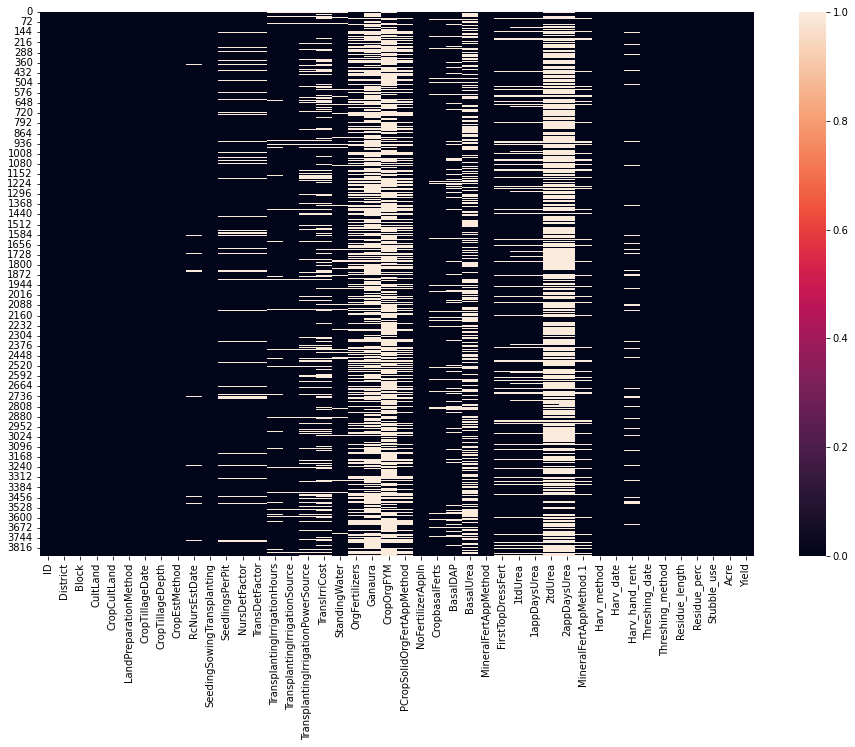

In [13]:
plt.figure(figsize=(16,10))
sns.heatmap(df.isna())

In [14]:
df[df.select_dtypes(np.number).columns].iloc[1:10]

,CultLand,CropCultLand,CropTillageDepth,SeedlingsPerPit,TransplantingIrrigationHours,TransIrriCost,StandingWater,Ganaura,CropOrgFYM,NoFertilizerAppln,BasalDAP,BasalUrea,1tdUrea,1appDaysUrea,2tdUrea,2appDaysUrea,Harv_hand_rent,Residue_length,Residue_perc,Acre,Yield
1,26,26,5,2.0,5.0,125.0,3.0,NaN,NaN,2,15.0,10.0,20.0,39.0,NaN,NaN,3.0,24,10,0.312500,600
2,10,10,6,2.0,4.0,80.0,2.0,1.0,1.0,2,4.0,NaN,5.0,65.0,NaN,NaN,480.0,30,10,0.148148,225
3,15,15,6,2.0,NaN,NaN,NaN,1.0,NaN,2,6.0,3.0,5.0,5.0,NaN,NaN,240.0,26,10,0.222222,468
4,60,60,4,2.0,9.0,300.0,2.0,NaN,NaN,2,15.0,30.0,30.0,26.0,NaN,NaN,NaN,24,40,0.468750,550
5,10,5,6,1.0,1.0,NaN,3.0,NaN,5.0,2,6.0,NaN,6.0,30.0,NaN,NaN,600.0,30,10,0.136364,205
6,12,12,3,4.0,1.0,NaN,6.0,1.0,NaN,3,3.0,NaN,4.0,28.0,6.0,67.0,130.0,25,10,0.136364,270
7,80,80,4,NaN,5.0,NaN,3.0,NaN,NaN,2,15.0,8.0,15.0,35.0,NaN,NaN,NaN,25,40,0.250000,490
8,25,25,4,4.0,2.0,NaN,5.0,NaN,2.0,3,5.0,NaN,5.0,20.0,7.0,58.0,130.0,26,10,0.227273,425
9,20,10,5,3.0,2.0,100.0,1.0,NaN,NaN,2,NaN,10.0,5.0,20.0,NaN,NaN,80.0,22,10,0.156250,300


<Figure size 1152x720 with 0 Axes>

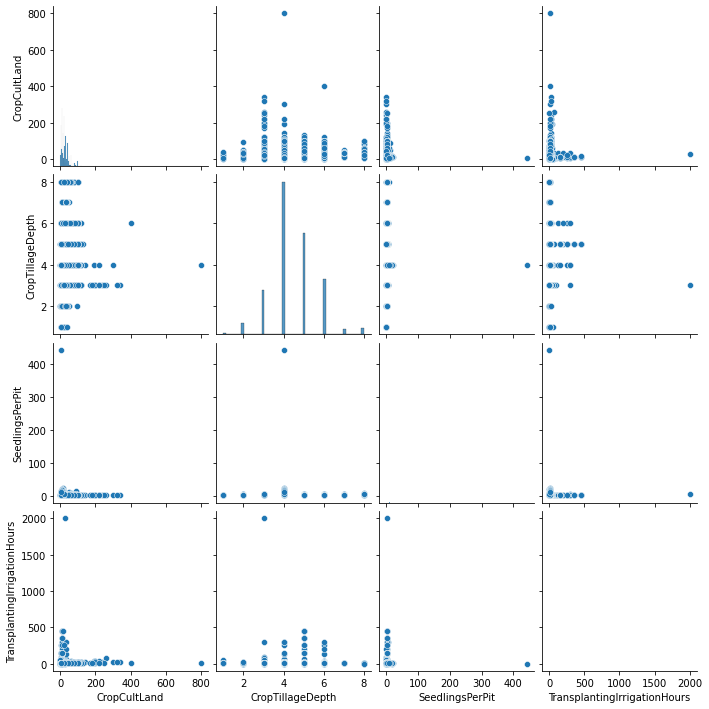

In [7]:
plt.figure(figsize=(16,10))
df_num=df[df.select_dtypes(np.number).columns]
df_num.fillna(0)
sns.pairplot(df_num.iloc[:,1:5])

In [8]:
df.columns[(df.isna().sum()*100/df.shape[0]).sort_values(ascending=False) < 0.5]

Index(['NoFertilizerAppln', 'CropbasalFerts', 'BasalDAP', 'BasalUrea',
       'MineralFertAppMethod', 'FirstTopDressFert', '1tdUrea', '1appDaysUrea',
       '2tdUrea', '2appDaysUrea', 'MineralFertAppMethod.1', 'Harv_method',
       'Harv_date', 'Harv_hand_rent', 'Threshing_date', 'Threshing_method',
       'Residue_length', 'Residue_perc', 'Stubble_use', 'Acre', 'Yield'],
      dtype='object')

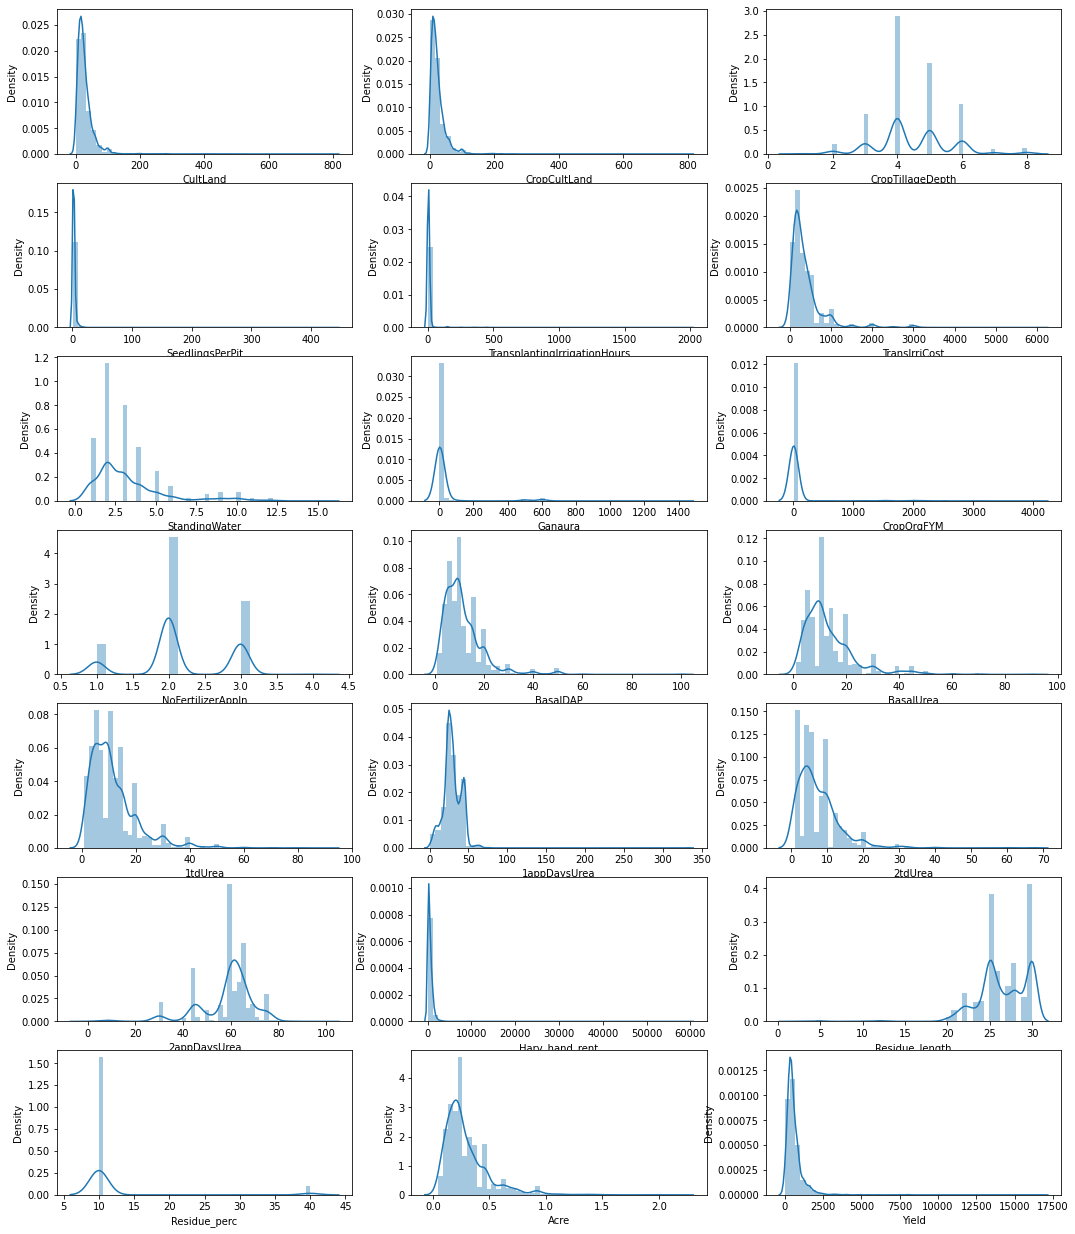

In [9]:
plt.figure(figsize=(18,25))

for i,col in enumerate(df.select_dtypes(np.number)):
    plt.subplot(8,3,i+1)
    sns.distplot(df[col])

In [16]:
def plot_outliers(columns, q):
    alpha = np.quantile(df[columns], q)
    mu = np.mean(df[columns])
    new = []
    for i in df[columns]:
        if i>=alpha:
            new.append(mu)
        else:
            new.append(i)

    plt.figure(figsize=(18,8))
    plt.subplot(2,3,1)
    plt.scatter(range(df.shape[0]),df[columns])
    plt.subplot(2,3,2)
    plt.boxplot(df[columns])
    plt.subplot(2,3,3)
    sns.distplot(df[columns])
    plt.subplot(2,3,4)
    plt.scatter(range(len(new)),new)
    plt.subplot(2,3,5)
    plt.boxplot(new)
    plt.subplot(2,3,6)
    sns.distplot(new)

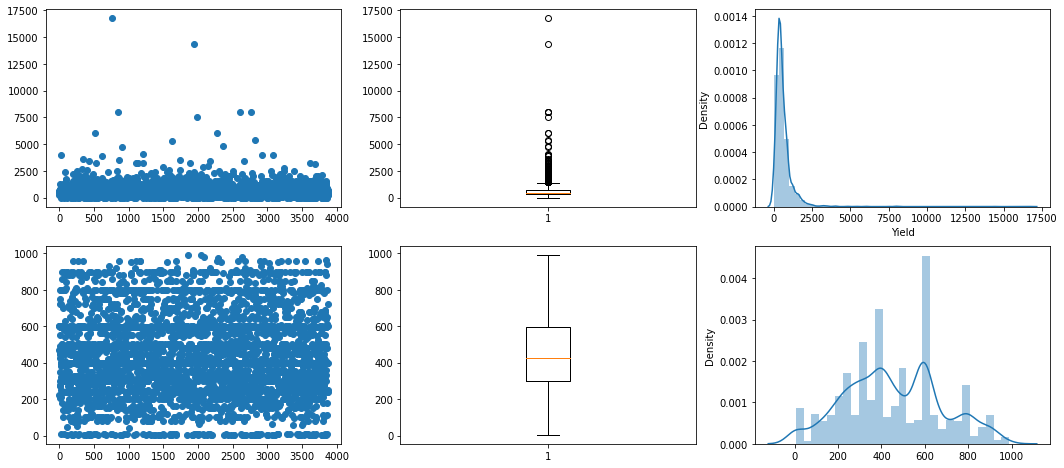

In [12]:
plot_outliers("Yield", 0.88)

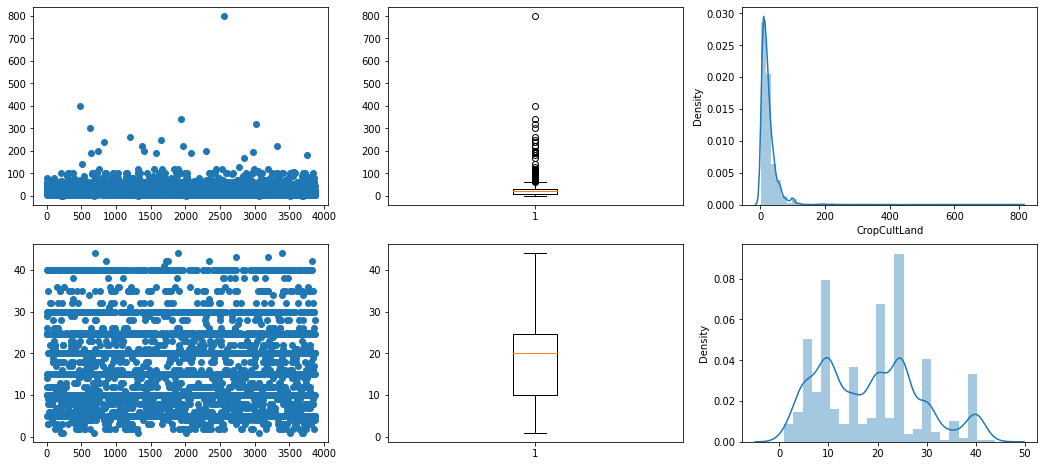

In [13]:
plot_outliers("CropCultLand", 0.88)

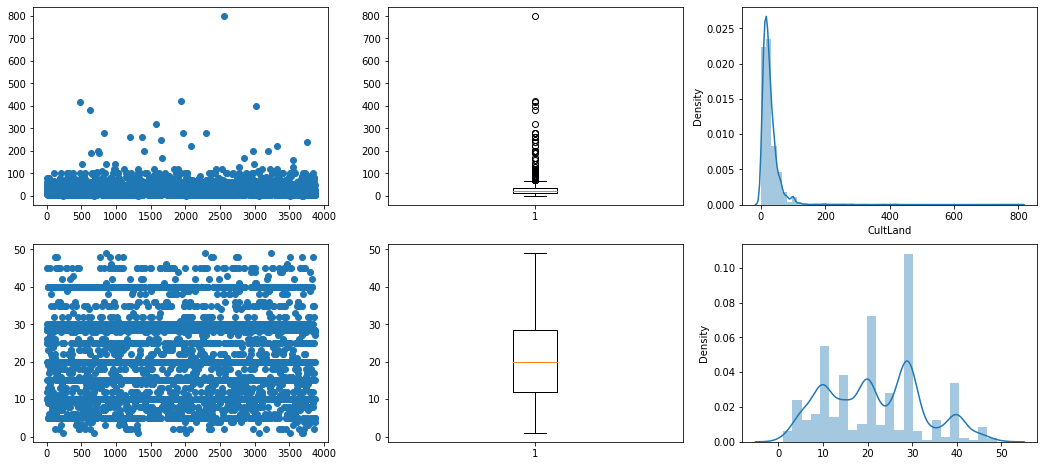

In [14]:
plot_outliers("CultLand", 0.88)

Text(0.5, 1.0, 'Acre vs Yield')

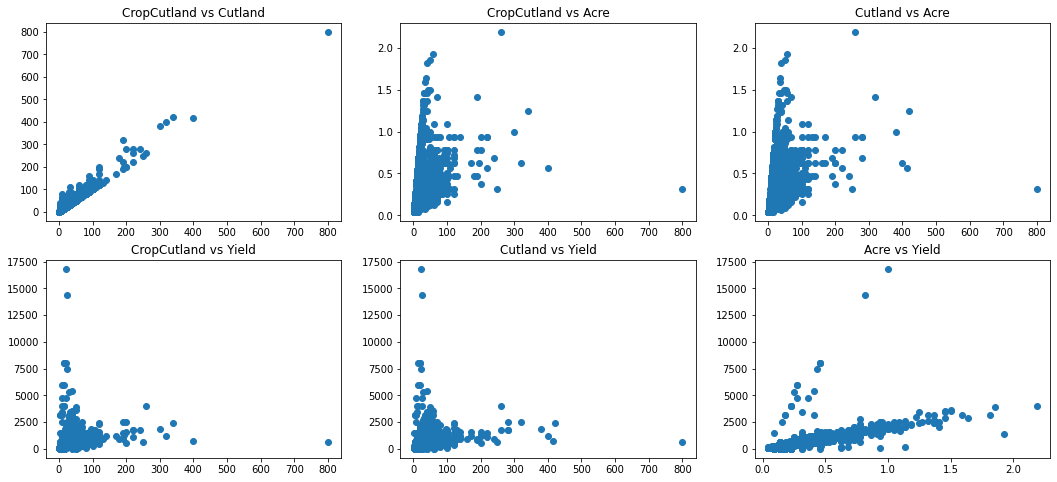

In [15]:
plt.figure(figsize=(18,8))
plt.subplot(2,3,1)
plt.scatter(df.CropCultLand,df.CultLand)
plt.title("CropCutland vs Cutland")
plt.subplot(2,3,2)
plt.scatter(df.CropCultLand,df.Acre)
plt.title("CropCutland vs Acre")
plt.subplot(2,3,3)
plt.scatter(df.CultLand,df.Acre)
plt.title("Cutland vs Acre")
plt.subplot(2,3,4)
plt.scatter(df.CropCultLand,df.Yield)
plt.title("CropCutland vs Yield")
plt.subplot(2,3,5)
plt.scatter(df.CultLand,df.Yield)
plt.title("Cutland vs Yield")
plt.subplot(2,3,6)
plt.scatter(df.Acre,df.Yield)
plt.title("Acre vs Yield")

In [31]:
df.Yield.apply(lambda x: x>np.quantile(df.Yield, 0.88)).map({True:"Anormal", False:"Normal"}).value_counts()

Normal     3419
Anormal     451
Name: Yield, dtype: int64

In [39]:
d=(set(df[df.Yield.apply(lambda x: x>np.quantile(df.Yield, 0.88))].index).intersection(df[df.CultLand.apply(lambda x: x>np.quantile(df.CultLand, 0.88))].index).intersection(df[df.CropCultLand.apply(lambda x: x>np.quantile(df.CropCultLand, 0.88))].index))

In [59]:
df.iloc[list(d)]

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,...,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield
1025,ID_TPPODBI64APR,Nalanda,Rajgir,80,60,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-14,3,Manual_PuddledRandom,2022-06-20,...,machine,2022-11-13,NaN,2022-11-13,machine,30,40,plowed_in_soil,0.625000,1200
515,ID_52QNZDVW1O3M,Nalanda,Noorsarai,140,140,TractorPlough,2022-07-17,4,Manual_PuddledRandom,2022-06-16,...,machine,2022-11-25,NaN,2022-11-28,machine,25,40,plowed_in_soil,0.937500,1200
1035,ID_PM217XX3MH09,Gaya,Gurua,60,60,TractorPlough FourWheelTracRotavator,2022-07-29,6,LineSowingAfterTillage,2022-07-30,...,hand,2022-12-09,1800.0,2022-12-31,machine,30,10,plowed_in_soil,0.555556,1395
1038,ID_IUZD1JFAQBHU,Nalanda,Rajgir,70,60,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-14,6,Manual_PuddledRandom,2022-06-27,...,hand,2022-12-06,600.0,2023-01-28,machine,25,10,plowed_in_soil,0.406250,1200
1551,ID_7S6CVJ47WAKQ,Nalanda,Noorsarai,120,120,TractorPlough FourWheelTracRotavator,2022-07-01,3,Manual_PuddledRandom,2022-06-05,...,machine,2022-10-05,NaN,2022-10-05,machine,22,40,plowed_in_soil,0.937500,2400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2030,ID_LPNG4H3P9ZXD,Nalanda,Rajgir,100,80,FourWheelTracRotavator TractorPlough,2022-06-15,8,LineSowingAfterTillage,2022-07-02,...,hand,2022-11-15,1500.0,2022-12-08,machine,25,10,plowed_in_soil,0.625000,1200
497,ID_KJFCEQMWKJQ4,Nalanda,Rajgir,70,60,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-14,6,Manual_PuddledRandom,2022-06-29,...,hand,2022-11-15,1100.0,2023-01-21,machine,24,10,plowed_in_soil,0.531250,1600
503,ID_E8P95YLQKXRT,Gaya,Wazirganj,80,60,WetTillagePuddling FourWheelTracRotavator,2022-07-03,5,Manual_PuddledRandom,2022-06-23,...,hand,2022-11-11,100.0,2022-11-20,hand,25,10,plowed_in_soil,0.740741,1600
1017,ID_85T0JU7UYXQM,Gaya,Gurua,70,70,FourWheelTracRotavator TractorPlough,2022-07-25,6,Manual_PuddledRandom,2022-06-16,...,hand,2022-12-05,1800.0,2022-12-15,hand,30,10,plowed_in_soil,0.555556,1395


In [15]:
df["Number_of_Method"]=df.LandPreparationMethod.apply(lambda x: len(x.split()))

In [71]:
df.select_dtypes(np.object_)

,ID,District,Block,LandPreparationMethod,CropTillageDate,CropEstMethod,RcNursEstDate,SeedingSowingTransplanting,NursDetFactor,TransDetFactor,TransplantingIrrigationSource,TransplantingIrrigationPowerSource,OrgFertilizers,PCropSolidOrgFertAppMethod,CropbasalFerts,MineralFertAppMethod,FirstTopDressFert,MineralFertAppMethod.1,Harv_method,Harv_date,Threshing_date,Threshing_method,Stubble_use
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,TractorPlough FourWheelTracRotavator,2022-07-20,Manual_PuddledRandom,2022-06-27,2022-07-21,CalendarDate IrrigWaterAvailability SeedAvaila...,CalendarDate SeedlingAge RainArrival IrrigWate...,Boring,Electric,NaN,NaN,Urea,Broadcasting,Urea,Broadcasting,machine,2022-11-16,2022-11-16,machine,plowed_in_soil
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-18,Manual_PuddledRandom,2022-06-20,2022-07-20,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,Boring,Electric,NaN,NaN,DAP Urea,Broadcasting,Urea,Broadcasting,hand,2022-11-25,2022-12-24,machine,plowed_in_soil
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,TractorPlough FourWheelTracRotavator,2022-06-30,Manual_PuddledRandom,2022-06-20,2022-08-13,PreMonsoonShowers IrrigWaterAvailability Labou...,SeedlingAge IrrigWaterAvailability LaborAvaila...,Boring,Electric,Ganaura FYM,SoilApplied,DAP,SoilApplied,Urea,RootApplication,hand,2022-12-12,2023-01-11,machine,plowed_in_soil
3,ID_I3IPXS4DB7NE,Gaya,Gurua,TractorPlough FourWheelTracRotavator,2022-06-16,Manual_PuddledRandom,2022-06-17,2022-07-17,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,NaN,NaN,Ganaura,SoilApplied,DAP Urea,Broadcasting,Urea,Broadcasting,hand,2022-12-02,2022-12-29,hand,plowed_in_soil
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,TractorPlough WetTillagePuddling,2022-07-19,Manual_PuddledRandom,2022-06-21,2022-07-20,CalendarDate IrrigWaterAvailability SeedAvaila...,SeedlingAge RainArrival IrrigWaterAvailability...,Boring,Electric,NaN,NaN,Urea DAP,Broadcasting,Urea,Broadcasting,machine,2022-11-30,2022-12-02,machine,plowed_in_soil
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,ID_7ZZQ6R4XB4FK,Nalanda,Rajgir,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-02,LineSowingAfterTillage,2022-06-29,2022-07-16,NaN,NaN,Boring,Electric,Ganaura,SoilApplied,DAP Urea,Broadcasting,Urea,Broadcasting,machine,2022-11-29,2022-12-14,machine,plowed_in_soil
3866,ID_PVVDF6LK6FO8,Vaishali,Mahua,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-06,Manual_PuddledRandom,2022-07-08,2022-07-30,IrrigWaterAvailability LabourAvailability,IrrigWaterAvailability LaborAvailability,Boring,Diesel,NaN,NaN,DAP,RootApplication,Urea,Broadcasting,hand,2022-10-10,2022-11-05,hand,plowed_in_soil
3867,ID_RBYVUPRATVMW,Nalanda,Noorsarai,TractorPlough,2022-07-07,Manual_PuddledRandom,2022-06-15,2022-07-08,CalendarDate IrrigWaterAvailability,CalendarDate IrrigWaterAvailability,Boring,Electric,Ganaura,Broadcasting,Urea,Broadcasting,NaN,NaN,hand,2022-10-20,2022-10-30,hand,plowed_in_soil
3868,ID_ARE9QWENJNJ2,Jamui,Khaira,TractorPlough,2022-07-12,Manual_PuddledRandom,2022-06-28,2022-07-24,SeedAvailability IrrigWaterAvailability,IrrigWaterAvailability RainArrival SeedlingAge,Canal,NaN,NaN,NaN,DAP Urea,Broadcasting,NaN,NaN,hand,2022-11-09,2022-12-10,hand,plowed_in_soil


In [73]:
df.OrgFertilizers.value_counts()

Ganaura                                    1295
FYM                                        1035
Ganaura FYM                                  84
Ganaura FYM Ghanajeevamrit                   26
VermiCompost                                 19
Ganaura FYM VermiCompost                     10
FYM Ganaura                                  10
Ganaura FYM VermiCompost Ghanajeevamrit      10
FYM VermiCompost                              8
Ganaura Ghanajeevamrit                        5
Ganaura VermiCompost Ghanajeevamrit           4
VermiCompost FYM                              4
Ganaura Jeevamrit                             2
Ganaura Pranamrit Ghanajeevamrit              2
Ghanajeevamrit Ganaura                        2
PoultryManure                                 2
Ganaura PoultryManure                         2
Ganaura Ghanajeevamrit FYM                    2
Ghanajeevamrit Ganaura FYM                    1
Ghanajeevamrit FYM Ganaura                    1
Ganaura Pranamrit FYM                   

In [74]:
df.CropbasalFerts.value_counts()

DAP Urea             1640
DAP                  1379
Urea                  308
Urea DAP              134
DAP Other              70
DAP Urea SSP           51
NPK                    29
DAP Urea NPKS          18
NPK Urea                8
Urea DAP SSP            7
Urea NPKS               6
Urea DAP NPKS           3
DAP SSP                 3
DAP NPKS                3
Urea NPKS DAP           3
DAP NPK Urea            2
NPKS                    1
DAP NPKS Urea SSP       1
Urea DAP MoP            1
DAP Urea NPK            1
SSP Urea                1
NPKS DAP Urea           1
DAP NPKS Urea           1
DAP Urea NPKS MoP       1
DAP Urea SSP MoP        1
Urea NPK                1
DAP NPKS Other          1
NPK DAP Urea            1
Urea SSP                1
DAP MoP                 1
DAP Urea NPKS SSP       1
DAP Urea MoP            1
Urea SSP DAP            1
Urea Other DAP          1
Name: CropbasalFerts, dtype: int64

In [77]:
df.PCropSolidOrgFertAppMethod.value_counts()

SoilApplied        1680
Broadcasting        841
RootApplication       9
Spray                 3
Name: PCropSolidOrgFertAppMethod, dtype: int64

In [78]:
df.MineralFertAppMethod.value_counts()

Broadcasting       3214
SoilApplied         638
RootApplication      18
Name: MineralFertAppMethod, dtype: int64

In [79]:
df.Harv_method.value_counts()

hand       3642
machine     228
Name: Harv_method, dtype: int64

In [80]:
df.FirstTopDressFert.value_counts()

Urea            2798
DAP Urea         322
Urea DAP         177
DAP               64
NPKS Urea          6
Urea NPKS          5
NPK                3
DAP NPKS           3
NPK Urea           2
DAP NPK Urea       1
Urea NPK           1
DAP NPK            1
Urea SSP           1
Other Urea         1
Name: FirstTopDressFert, dtype: int64

In [81]:
df.MineralFertAppMethod

0          Broadcasting
1          Broadcasting
2           SoilApplied
3          Broadcasting
4          Broadcasting
             ...       
3865       Broadcasting
3866    RootApplication
3867       Broadcasting
3868       Broadcasting
3869       Broadcasting
Name: MineralFertAppMethod, Length: 3870, dtype: object

In [85]:
(df.isna().sum()*100/df.shape[0]).sort_values(ascending=False)

2appDaysUrea                          69.767442
2tdUrea                               69.612403
CropOrgFYM                            69.095607
Ganaura                               62.454780
BasalUrea                             44.031008
PCropSolidOrgFertAppMethod            34.547804
OrgFertilizers                        34.496124
TransIrriCost                         22.790698
1appDaysUrea                          14.366925
1tdUrea                               14.366925
BasalDAP                              14.031008
TransplantingIrrigationPowerSource    12.997416
FirstTopDressFert                     12.532300
MineralFertAppMethod.1                12.428941
NursDetFactor                          7.467700
SeedlingsPerPit                        7.467700
TransDetFactor                         7.467700
Harv_hand_rent                         6.511628
StandingWater                          6.149871
TransplantingIrrigationHours           4.987080
CropbasalFerts                         4

In [104]:
df.CropbasalFerts

0           Urea
1       DAP Urea
2            DAP
3       DAP Urea
4       Urea DAP
          ...   
3865    DAP Urea
3866         DAP
3867        Urea
3868    DAP Urea
3869    DAP Urea
Name: CropbasalFerts, Length: 3870, dtype: object

In [107]:
df.NoFertilizerAppln.value_counts(normalize=True)

2    0.568734
3    0.305168
1    0.124289
4    0.001809
Name: NoFertilizerAppln, dtype: float64

In [110]:
(0.305168+0.001809)-1

-0.693023

In [102]:
df.CropbasalFerts.map(str).apply(lambda x: len(x.split()))

0       1
1       2
2       1
3       2
4       2
       ..
3865    2
3866    1
3867    1
3868    2
3869    2
Name: CropbasalFerts, Length: 3870, dtype: int64

In [103]:
df.FirstTopDressFert

0       Urea
1       Urea
2       Urea
3       Urea
4       Urea
        ... 
3865    Urea
3866    Urea
3867     NaN
3868     NaN
3869    Urea
Name: FirstTopDressFert, Length: 3870, dtype: object

In [105]:
df["2tdUrea"]

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
3865    NaN
3866    6.0
3867    NaN
3868    NaN
3869    NaN
Name: 2tdUrea, Length: 3870, dtype: float64

In [35]:
a = "kdld"
{f"{a}__{i}":i for i in range(5) if i==4}

{'kdld__0': 0, 'kdld__1': 1, 'kdld__2': 2, 'kdld__3': 3, 'kdld__4': 4}

In [18]:
df.LandPreparationMethod.apply(lambda x: len(x.split())).max()

4

In [123]:
def somme(x,a):
    return x+a


pd.Series([1,2,4,5]).apply(lambda x: somme(x,10))

0    11
1    12
2    14
3    15
dtype: int64

In [124]:
df.apply(lambda x: pd.Series([1, 2], index=['foo', 'bar']), axis=1)

,foo,bar
0,1,2
1,1,2
2,1,2
3,1,2
4,1,2
...,...,...
3865,1,2
3866,1,2
3867,1,2
3868,1,2


In [70]:
df.head()

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,SeedingSowingTransplanting,SeedlingsPerPit,NursDetFactor,TransDetFactor,TransplantingIrrigationHours,TransplantingIrrigationSource,TransplantingIrrigationPowerSource,TransIrriCost,StandingWater,OrgFertilizers,Ganaura,CropOrgFYM,PCropSolidOrgFertAppMethod,NoFertilizerAppln,CropbasalFerts,BasalDAP,BasalUrea,MineralFertAppMethod,FirstTopDressFert,1tdUrea,1appDaysUrea,2tdUrea,2appDaysUrea,MineralFertAppMethod.1,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,45,40,TractorPlough FourWheelTracRotavator,2022-07-20,5,Manual_PuddledRandom,2022-06-27,2022-07-21,2.0,CalendarDate IrrigWaterAvailability SeedAvaila...,CalendarDate SeedlingAge RainArrival IrrigWate...,5.0,Boring,Electric,200.0,2.0,NaN,NaN,NaN,NaN,2,Urea,NaN,20.0,Broadcasting,Urea,15.0,18.0,NaN,NaN,Broadcasting,machine,2022-11-16,NaN,2022-11-16,machine,30,40,plowed_in_soil,0.312500,600
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,26,26,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-18,5,Manual_PuddledRandom,2022-06-20,2022-07-20,2.0,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,5.0,Boring,Electric,125.0,3.0,NaN,NaN,NaN,NaN,2,DAP Urea,15.0,10.0,Broadcasting,Urea,20.0,39.0,NaN,NaN,Broadcasting,hand,2022-11-25,3.0,2022-12-24,machine,24,10,plowed_in_soil,0.312500,600
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,10,10,TractorPlough FourWheelTracRotavator,2022-06-30,6,Manual_PuddledRandom,2022-06-20,2022-08-13,2.0,PreMonsoonShowers IrrigWaterAvailability Labou...,SeedlingAge IrrigWaterAvailability LaborAvaila...,4.0,Boring,Electric,80.0,2.0,Ganaura FYM,1.0,1.0,SoilApplied,2,DAP,4.0,NaN,SoilApplied,Urea,5.0,65.0,NaN,NaN,RootApplication,hand,2022-12-12,480.0,2023-01-11,machine,30,10,plowed_in_soil,0.148148,225
3,ID_I3IPXS4DB7NE,Gaya,Gurua,15,15,TractorPlough FourWheelTracRotavator,2022-06-16,6,Manual_PuddledRandom,2022-06-17,2022-07-17,2.0,CalendarDate PreMonsoonShowers IrrigWaterAvail...,CalendarDate SeedlingAge RainArrival IrrigWate...,NaN,NaN,NaN,NaN,NaN,Ganaura,1.0,NaN,SoilApplied,2,DAP Urea,6.0,3.0,Broadcasting,Urea,5.0,5.0,NaN,NaN,Broadcasting,hand,2022-12-02,240.0,2022-12-29,hand,26,10,plowed_in_soil,0.222222,468
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,60,60,TractorPlough WetTillagePuddling,2022-07-19,4,Manual_PuddledRandom,2022-06-21,2022-07-20,2.0,CalendarDate IrrigWaterAvailability SeedAvaila...,SeedlingAge RainArrival IrrigWaterAvailability...,9.0,Boring,Electric,300.0,2.0,NaN,NaN,NaN,NaN,2,Urea DAP,15.0,30.0,Broadcasting,Urea,30.0,26.0,NaN,NaN,Broadcasting,machine,2022-11-30,NaN,2022-12-02,machine,24,40,plowed_in_soil,0.468750,550


In [4]:
def fill_implicit_missing(df):
    df.Ganaura = np.where((df.OrgFertilizers.notna() & df.OrgFertilizers.apply(lambda x: ("ganaura" not in str(x).lower().split()))), 0, df.Ganaura.values)
    df.OrgFertilizers = np.where((df.OrgFertilizers.notna() & df.OrgFertilizers.apply(lambda x: ("fym" not in str(x).lower().split()))), 0, df.CropOrgFYM.values)
    df.BasalUrea = np.where((df.CropbasalFerts.notna() & df.CropbasalFerts.apply(lambda x: ("urea" not in str(x).lower().split()))),0,df.BasalUrea.values)
    df.BasalDAP = np.where((df.CropbasalFerts.notna() & df.CropbasalFerts.apply(lambda x: ("dap" not in str(x).lower().split()))),0,df.BasalDAP.values)
    df["1tdUrea"] = np.where((df.NoFertilizerAppln.notna() & df.NoFertilizerAppln==1),0,df["1tdUrea"].values)
    df["1appDaysUrea"] = np.where((df.NoFertilizerAppln.notna() & df.NoFertilizerAppln==1),0,df["1appDaysUrea"].values)
    df["2tdUrea"] = np.where((df.NoFertilizerAppln.notna() & df.NoFertilizerAppln==2),0,df["2tdUrea"].values)
    df["2appDaysUrea"] = np.where((df.NoFertilizerAppln.notna() & df.NoFertilizerAppln==2),0,df["2appDaysUrea"].values)

